<a href="https://colab.research.google.com/github/Prodi-TI-IBIKesatuan/pcd2026-ti23ka-t3/blob/t3-data%26anotasi-helena/notebooks/01_dataset_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Restorasi Citra Terdegradasi — Tahap 1: dataset dan preprocessing

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Prodi-TI-IBIKesatuan/pcd2026-ti23ka-t3/blob/main/notebooks/01_dataset_preprocessing.ipynb)

Kelompok `pcd2026-ti23ka-t3` · 4 anggota · minimal **200 citra** (termasuk 60 foto sendiri).

Notebook ini membaca dataset dari folder Google Drive kelompok, memeriksa anotasi, menerapkan preprocessing, dan menyimpan gambar sebelum–sesudah. Jalankan dari atas ke bawah.

In [11]:
import pathlib
import subprocess
import sys
import shutil
import csv
import os

import cv2
import numpy as np

REPO = "Prodi-TI-IBIKesatuan/pcd2026-ti23ka-t3"

try:
    import google.colab
    DI_COLAB = True
except ImportError:
    DI_COLAB = False

if DI_COLAB:
    AKAR = pathlib.Path("/content/repo")

    if AKAR.exists():
        subprocess.run(
            ["git", "-C", str(AKAR), "pull", "-q"],
            check=False
        )
    else:
        subprocess.run(
            [
                "git", "clone", "-q", "--depth", "1",
                f"https://github.com/{REPO}.git",
                str(AKAR)
            ],
            check=True
        )

    from google.colab import drive
    drive.mount("/content/drive")

    FOLDER_KERJA = pathlib.Path(
        "/content/drive/MyDrive/pcd2026-ti23ka-t3"
    )

    if not FOLDER_KERJA.exists():
        raise FileNotFoundError(
            f"{FOLDER_KERJA} tidak ada. "
            "Tambahkan pintasan folder Drive kelompok ke Drive Saya."
        )

else:
    AKAR = pathlib.Path.cwd().resolve().parent
    FOLDER_KERJA = AKAR / "data"

sys.path.insert(0, str(AKAR))

from pcd_proyek import evaluasi as ev, metrik, util

# Lokasi folder
FOLDER_CITRA = FOLDER_KERJA / "citra"

FOLDER_MASUK = FOLDER_CITRA / "foto_masuk"
FOLDER_BERSIH = FOLDER_CITRA / "citra_bersih"
FOLDER_RUSAK = FOLDER_CITRA / "citra_rusak"
FOLDER_FIGUR = FOLDER_CITRA / "figures"

BERKAS_ANOTASI = FOLDER_KERJA / "anotasi.csv"
BERKAS_HASIL = FOLDER_KERJA / "hasil_metode.json"

KOLOM_ANOTASI = [
    "berkas_bersih",
    "berkas_rusak",
    "jenis_degradasi",
    "parameter"
]

JUMLAH_ANGGOTA = 4

# Format gambar yang didukung
EXTENSI_GAMBAR = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".tif", ".tiff", ".webp"
}

# Membuat folder jika belum tersedia
for folder in [
    FOLDER_MASUK,
    FOLDER_BERSIH,
    FOLDER_RUSAK,
    FOLDER_FIGUR
]:
    folder.mkdir(parents=True, exist_ok=True)

# Mengambil semua gambar langsung dari folder, tanpa subfolder
def daftar_file_gambar(folder):
    return sorted(
        [
            p for p in pathlib.Path(folder).iterdir()
            if p.is_file() and p.suffix.lower() in EXTENSI_GAMBAR
        ],
        key=lambda p: p.name.lower()
    )

print("Folder kerja :", FOLDER_KERJA)
print("Foto masuk   :", FOLDER_MASUK)
print("Citra bersih :", FOLDER_BERSIH)
print("Citra rusak  :", FOLDER_RUSAK)
print("Anotasi      :", BERKAS_ANOTASI)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder kerja : /content/drive/MyDrive/pcd2026-ti23ka-t3
Foto masuk   : /content/drive/MyDrive/pcd2026-ti23ka-t3/citra/foto_masuk
Citra bersih : /content/drive/MyDrive/pcd2026-ti23ka-t3/citra/citra_bersih
Citra rusak  : /content/drive/MyDrive/pcd2026-ti23ka-t3/citra/citra_rusak
Anotasi      : /content/drive/MyDrive/pcd2026-ti23ka-t3/anotasi.csv


## 1. Statistik dataset

STATISTIK DATASET SUMBER
Jumlah foto : 250
Terbaca     : 250
Lebar       : {'min': 720, 'median': 2040, 'maks': 5865}
Tinggi      : {'min': 608, 'median': 1356, 'maks': 5443}

Target minimal 200 foto terpenuhi.


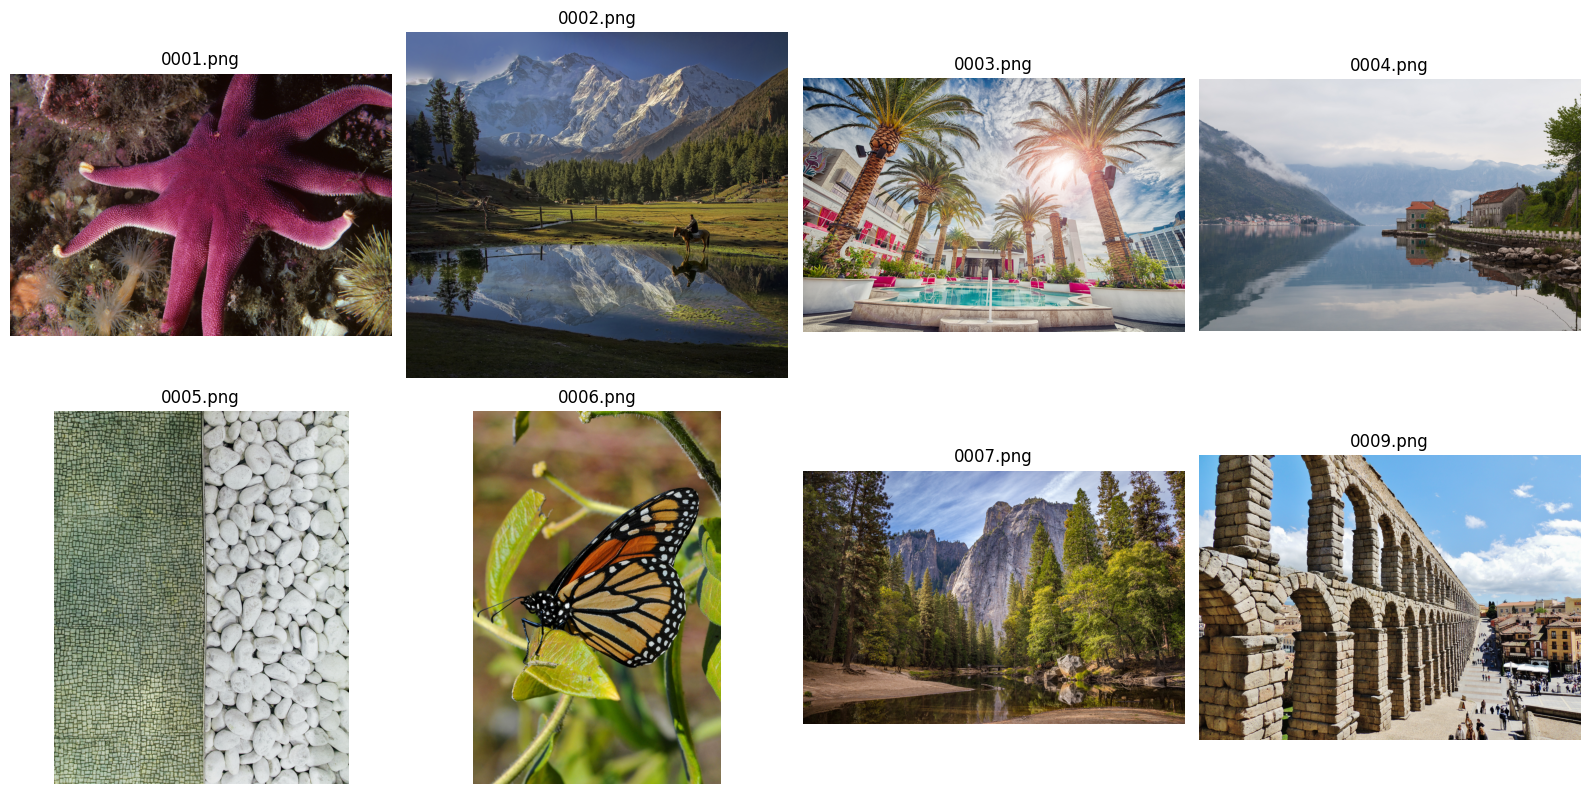

In [12]:
berkas = daftar_file_gambar(FOLDER_MASUK)

if not berkas:
    raise RuntimeError(
        f"Tidak ada gambar di {FOLDER_MASUK}. "
        "Masukkan foto terlebih dahulu."
    )

stat = util.statistik_dataset(berkas)

print("STATISTIK DATASET SUMBER")
print("========================")
print("Jumlah foto :", stat["jumlah"])
print("Terbaca     :", stat["terbaca"])
print("Lebar       :", stat.get("lebar"))
print("Tinggi      :", stat.get("tinggi"))

if stat["gagal"]:
    print(
        "\nGambar gagal dibaca (perlu diperiksa):",
        *stat["gagal"][:10],
        sep="\n- "
    )

if stat["jumlah"] < 200:
    print(
        f"\nPERINGATAN: jumlah foto {stat['jumlah']}. "
        "Target minimal kelompok adalah 200 foto."
    )
else:
    print("\nTarget minimal 200 foto terpenuhi.")

# Menampilkan maksimal 8 foto sumber
jumlah_tampil = min(8, len(berkas))

util.tampil(
    *[util.baca_citra(p) for p in berkas[:jumlah_tampil]],
    judul=[p.name for p in berkas[:jumlah_tampil]],
    kolom=4
)

## 2. Fungsi degradasi dan pengecekan status

Memeriksa apakah file bersih, file rusak, dan anotasi sudah lengkap


In [13]:
def degradasi(citra, seed=42, sigma=25):

    citra_float = citra.astype(np.float32)

    rng = np.random.default_rng(seed)

    noise = rng.normal(
        loc=0,
        scale=sigma,
        size=citra.shape
    )

    citra_rusak = np.clip(
        citra_float + noise,
        0,
        255
    ).astype(np.uint8)

    parameter = f"sigma={sigma};seed={seed}"

    return citra_rusak, parameter


def cek_status_a1():

    if not BERKAS_ANOTASI.exists():
        return False

    try:
        with open(
            BERKAS_ANOTASI,
            "r",
            newline="",
            encoding="utf-8"
        ) as file:
            reader = csv.DictReader(file)

            if reader.fieldnames != KOLOM_ANOTASI:
                return False

            anotasi = list(reader)

        if not anotasi:
            return False

        # Memeriksa jumlah file
        file_bersih = daftar_file_gambar(FOLDER_BERSIH)
        file_rusak = daftar_file_gambar(FOLDER_RUSAK)

        if len(file_bersih) != len(anotasi):
            return False

        if len(file_rusak) != len(anotasi):
            return False

        # Memeriksa setiap pasangan dalam anotasi
        for baris in anotasi:

            if not all(baris.get(kolom) for kolom in KOLOM_ANOTASI):
                return False

            path_bersih = FOLDER_CITRA / baris["berkas_bersih"]
            path_rusak = FOLDER_CITRA / baris["berkas_rusak"]

            if not path_bersih.is_file():
                return False

            if not path_rusak.is_file():
                return False

            if baris["jenis_degradasi"] != "gauss":
                return False

            if not baris["parameter"]:
                return False

        # Memastikan tidak ada nama file yang tercatat berulang
        nama_bersih = [x["berkas_bersih"] for x in anotasi]
        nama_rusak = [x["berkas_rusak"] for x in anotasi]

        if len(set(nama_bersih)) != len(nama_bersih):
            return False

        if len(set(nama_rusak)) != len(nama_rusak):
            return False

        return True

    except Exception:
        return False


STATUS_A1 = cek_status_a1()

print("Fungsi Gaussian Noise siap digunakan.")
print(
    "Status A1:",
    "SUDAH SELESAI" if STATUS_A1 else "BELUM SELESAI"
)

Fungsi Gaussian Noise siap digunakan.
Status A1: BELUM SELESAI


## 3. Proses penyalinan, degradasi, dan pembuatan anotasi



In [14]:
LOCK_A1 = FOLDER_KERJA / ".a1_processing.lock"

if STATUS_A1:

    print("A1 SUDAH SELESAI.")
    print("Penyalinan citra dilewati.")
    print("Pembuatan Gaussian Noise dilewati.")
    print("Pembuatan anotasi dilewati.")

else:

    # Mengunci proses agar tidak dijalankan bersamaan
    try:
        LOCK_A1.mkdir()
    except FileExistsError:
        raise RuntimeError(
            "Proses A1 sedang berjalan atau terdapat kunci "
            "dari proses sebelumnya. Jangan jalankan Cell 4 "
            "secara bersamaan. Periksa dahulu apakah anggota "
            "lain sedang memproses dataset."
        )

    try:
        # Periksa ulang setelah mendapatkan kunci
        STATUS_A1 = cek_status_a1()

        if STATUS_A1:
            print("A1 ternyata sudah selesai.")
            print("Tidak ada pemrosesan ulang.")

        else:

            # Pastikan belum ada hasil parsial dari proses sebelumnya
            if (
                daftar_file_gambar(FOLDER_BERSIH)
                or daftar_file_gambar(FOLDER_RUSAK)
                or BERKAS_ANOTASI.exists()
                or (FOLDER_KERJA / "anotasi.csv.tmp").exists()
            ):
                raise RuntimeError(
                    "Ditemukan hasil proses A1 sebelumnya yang "
                    "belum lengkap. Jangan hapus otomatis. "
                    "Periksa file di citra_bersih, citra_rusak, "
                    "dan anotasi.csv terlebih dahulu."
                )

            # A. Ambil dan periksa foto dari foto_masuk
            file_masuk = daftar_file_gambar(FOLDER_MASUK)

            if not file_masuk:
                raise RuntimeError(
                    "Tidak ada gambar di foto_masuk."
                )

            citra_bersih = []
            file_tidak_terbaca = []

            print("Mulai menyalin citra bersih...")

            for file_sumber in file_masuk:

                citra = cv2.imread(
                    str(file_sumber),
                    cv2.IMREAD_COLOR
                )

                if citra is None:
                    file_tidak_terbaca.append(file_sumber.name)
                    continue

                nomor = len(citra_bersih) + 1

                nama_bersih = (
                    f"bersih_{nomor:03d}"
                    f"{file_sumber.suffix.lower()}"
                )

                path_bersih = FOLDER_BERSIH / nama_bersih

                # Salin file asli tanpa mengubah format atau kualitas
                shutil.copy2(file_sumber, path_bersih)

                citra_bersih.append(path_bersih)

            print("Citra bersih berhasil disalin:", len(citra_bersih))
            print("Citra gagal dibaca:", len(file_tidak_terbaca))

            if file_tidak_terbaca:
                print(
                    "File yang dilewati:",
                    *file_tidak_terbaca[:20],
                    sep="\n- "
                )

            if not citra_bersih:
                raise RuntimeError(
                    "Tidak ada citra yang berhasil disalin."
                )

            if len(citra_bersih) < 200:
                print("PERINGATAN: jumlah citra belum mencapai 200.")
            else:
                print("Target minimal 200 citra terpenuhi.")

            # B. Membuat citra rusak dengan Gaussian Noise
            SEED_AWAL = 42
            SIGMA = 25

            data_anotasi = []

            print("\nMulai membuat Gaussian Noise...")

            for i, path_bersih in enumerate(citra_bersih, start=1):

                citra = cv2.imread(
                    str(path_bersih),
                    cv2.IMREAD_COLOR
                )

                if citra is None:
                    raise RuntimeError(
                        f"Citra bersih gagal dibaca: {path_bersih.name}"
                    )

                seed = SEED_AWAL + i - 1

                hasil_rusak, parameter = degradasi(
                    citra,
                    seed=seed,
                    sigma=SIGMA
                )

                nama_rusak = f"rusak_{i:03d}_noise.png"
                path_rusak = FOLDER_RUSAK / nama_rusak

                berhasil = cv2.imwrite(
                    str(path_rusak),
                    hasil_rusak
                )

                if not berhasil:
                    raise RuntimeError(
                        f"Gagal menyimpan citra rusak: {nama_rusak}"
                    )

                # C. Menyiapkan baris anotasi
                data_anotasi.append({
                    "berkas_bersih": path_bersih.relative_to(
                        FOLDER_CITRA
                    ).as_posix(),

                    "berkas_rusak": path_rusak.relative_to(
                        FOLDER_CITRA
                    ).as_posix(),

                    "jenis_degradasi": "gauss",

                    "parameter": parameter
                })

            # Pastikan jumlah pasangan sama
            if len(data_anotasi) != len(citra_bersih):
                raise RuntimeError(
                    "Jumlah citra bersih dan rusak tidak sama."
                )

            # D. Simpan anotasi sementara terlebih dahulu
            BERKAS_ANOTASI_SEMENTARA = (
                FOLDER_KERJA / "anotasi.csv.tmp"
            )

            with open(
                BERKAS_ANOTASI_SEMENTARA,
                "w",
                newline="",
                encoding="utf-8"
            ) as file:

                writer = csv.DictWriter(
                    file,
                    fieldnames=KOLOM_ANOTASI
                )

                writer.writeheader()
                writer.writerows(data_anotasi)

                file.flush()
                os.fsync(file.fileno())

            # Mengubah nama file sementara menjadi anotasi.csv
            BERKAS_ANOTASI_SEMENTARA.replace(BERKAS_ANOTASI)

            print("\nPROSES A1 SELESAI.")
            print("Jumlah citra bersih :", len(citra_bersih))
            print("Jumlah citra rusak  :", len(data_anotasi))
            print("Jumlah anotasi      :", len(data_anotasi))
            print("Anotasi tersimpan   :", BERKAS_ANOTASI)

    finally:
        # Membuka kunci setelah proses selesai atau mengalami error
        if LOCK_A1.exists():
            shutil.rmtree(LOCK_A1, ignore_errors=True)

Mulai menyalin citra bersih...
Citra bersih berhasil disalin: 250
Citra gagal dibaca: 0
Target minimal 200 citra terpenuhi.

Mulai membuat Gaussian Noise...

PROSES A1 SELESAI.
Jumlah citra bersih : 250
Jumlah citra rusak  : 250
Jumlah anotasi      : 250
Anotasi tersimpan   : /content/drive/MyDrive/pcd2026-ti23ka-t3/anotasi.csv


## 4. Validasi hasil proses

In [15]:
if not BERKAS_ANOTASI.exists():
    raise FileNotFoundError("anotasi.csv belum tersedia.")

with open(
    BERKAS_ANOTASI,
    "r",
    newline="",
    encoding="utf-8"
) as file:
    anotasi = list(csv.DictReader(file))

file_bersih = daftar_file_gambar(FOLDER_BERSIH)
file_rusak = daftar_file_gambar(FOLDER_RUSAK)

print("HASIL VALIDASI")
print("==============")
print("Jumlah citra bersih :", len(file_bersih))
print("Jumlah citra rusak  :", len(file_rusak))
print("Jumlah baris anotasi:", len(anotasi))

# Periksa jumlah file
if not (
    len(file_bersih) == len(file_rusak) == len(anotasi)
):
    raise RuntimeError(
        "Jumlah citra bersih, citra rusak, dan anotasi tidak sama."
    )

# Periksa keberadaan file pada setiap baris anotasi
hilang = []

for baris in anotasi:

    path_bersih = FOLDER_CITRA / baris["berkas_bersih"]
    path_rusak = FOLDER_CITRA / baris["berkas_rusak"]

    if not path_bersih.is_file():
        hilang.append(str(path_bersih))

    if not path_rusak.is_file():
        hilang.append(str(path_rusak))

if hilang:
    print("\nFile yang tidak ditemukan:")
    for nama in hilang[:20]:
        print("-", nama)

    raise RuntimeError("Validasi gagal karena ada file yang hilang.")

# Periksa jenis degradasi dan parameter
if any(baris["jenis_degradasi"] != "gauss" for baris in anotasi):
    raise RuntimeError("Ditemukan jenis degradasi yang tidak sesuai.")

if any(not baris["parameter"] for baris in anotasi):
    raise RuntimeError("Ada parameter degradasi yang kosong.")

# Periksa apakah semua citra dapat dibaca
gagal_baca = []

for path in file_bersih + file_rusak:
    if cv2.imread(str(path), cv2.IMREAD_COLOR) is None:
        gagal_baca.append(path.name)

if gagal_baca:
    print("File gagal dibaca:", gagal_baca[:20])
    raise RuntimeError("Ada citra yang gagal dibaca.")

STATUS_A1 = cek_status_a1()

if STATUS_A1:
    print("\nSTATUS A1: LENGKAP DAN VALID.")
else:
    raise RuntimeError("STATUS A1 belum valid.")

HASIL VALIDASI
Jumlah citra bersih : 250
Jumlah citra rusak  : 250
Jumlah baris anotasi: 250

STATUS A1: LENGKAP DAN VALID.


## 5.Statistik citra bersih

STATISTIK CITRA BERSIH
Jumlah citra: 250
Terbaca     : 250
Lebar       : {'min': 720, 'median': 2040, 'maks': 5865}
Tinggi      : {'min': 608, 'median': 1356, 'maks': 5443}


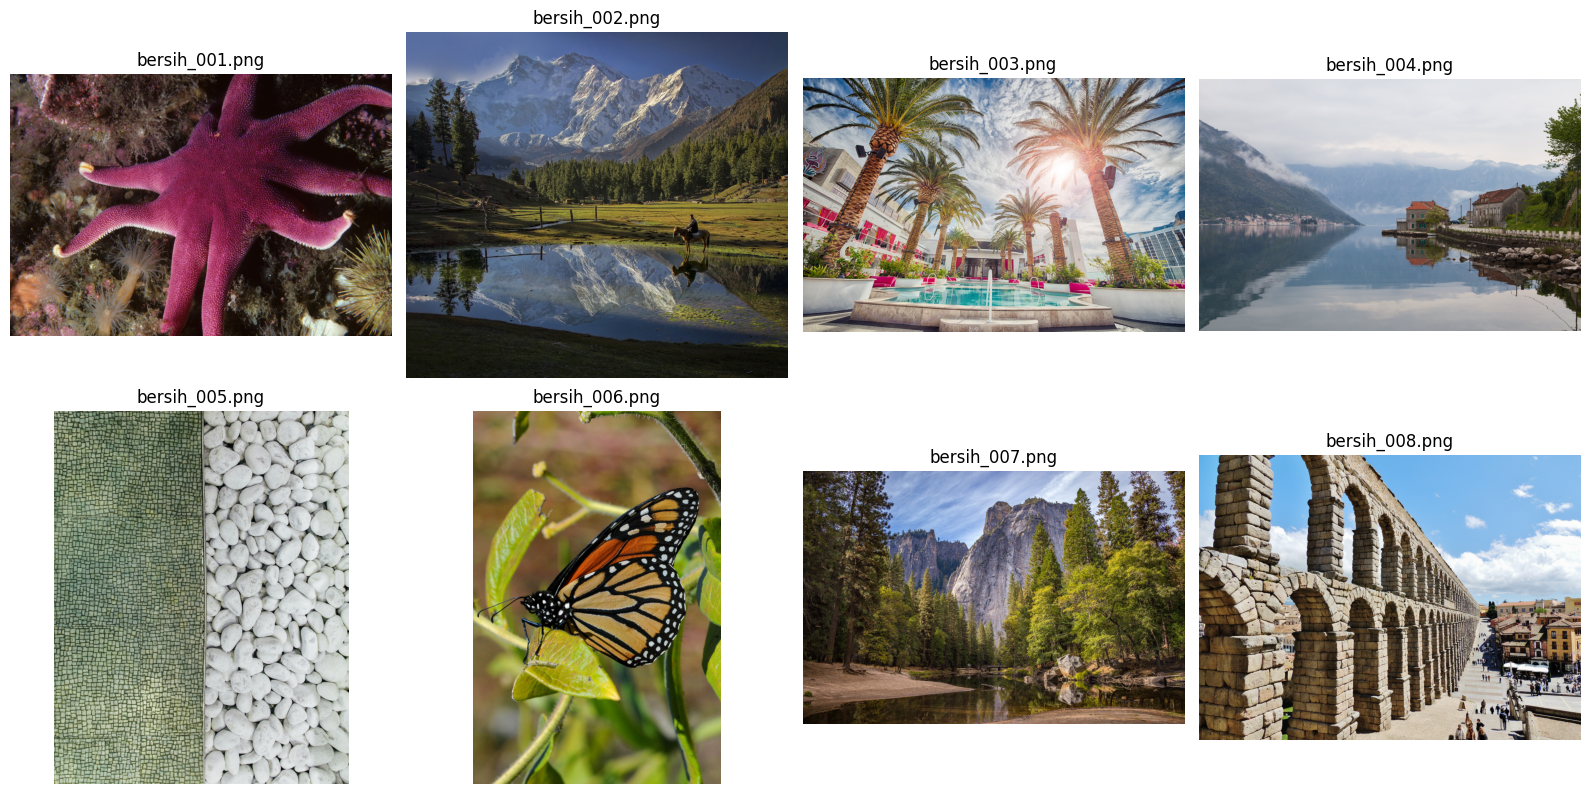

In [16]:
berkas = daftar_file_gambar(FOLDER_BERSIH)

if not berkas:
    raise RuntimeError("Tidak ada citra bersih.")

stat = util.statistik_dataset(berkas)

print("STATISTIK CITRA BERSIH")
print("======================")
print("Jumlah citra:", stat["jumlah"])
print("Terbaca     :", stat["terbaca"])
print("Lebar       :", stat.get("lebar"))
print("Tinggi      :", stat.get("tinggi"))

if stat["gagal"]:
    print(
        "Citra gagal dibaca:",
        *stat["gagal"][:10],
        sep="\n- "
    )

jumlah_tampil = min(8, len(berkas))

util.tampil(
    *[util.baca_citra(p) for p in berkas[:jumlah_tampil]],
    judul=[p.name for p in berkas[:jumlah_tampil]],
    kolom=4
)

## 6.Cek anotasi

In [19]:
KOLOM_BERKAS = ['berkas_bersih', 'berkas_rusak']

if BERKAS_ANOTASI.exists():
    anotasi = util.baca_anotasi(
        BERKAS_ANOTASI,
        KOLOM_ANOTASI
    )

    cek = util.cek_anotasi(
        anotasi,
        FOLDER_CITRA,
        KOLOM_BERKAS
    )

    print("PEMERIKSAAN ANOTASI")
    print("==================")
    print(len(anotasi), "baris anotasi")
    print(
        "Disebut di anotasi tetapi berkasnya tidak ada:",
        cek["hilang"][:20]
    )

    file_bersih = daftar_file_gambar(FOLDER_BERSIH)
    file_rusak = daftar_file_gambar(FOLDER_RUSAK)

    jumlah_anotasi = len(anotasi)

    print("\nVALIDASI HASIL A1")
    print("=================")
    print("Citra bersih :", len(file_bersih))
    print("Citra rusak  :", len(file_rusak))
    print("Baris anotasi:", jumlah_anotasi)

    if len(file_bersih) == len(file_rusak) == jumlah_anotasi:
        print("Status: Jumlah citra dan anotasi sesuai.")
    else:
        print("Status: Jumlah citra dan anotasi belum sesuai.")

else:
    print("anotasi.csv belum ada di", BERKAS_ANOTASI)

PEMERIKSAAN ANOTASI
250 baris anotasi
Disebut di anotasi tetapi berkasnya tidak ada: []

VALIDASI HASIL A1
Citra bersih : 250
Citra rusak  : 250
Baris anotasi: 250
Status: Jumlah citra dan anotasi sesuai.


## 7. Preprocessing

Saran untuk topik ini: skrip pembuat degradasi dengan seed tetap; resize atau crop seragam; konversi ke float [0, 1] untuk perhitungan.

Sel kode di bawah hanya **kerangka dummy**. Ganti dengan langkah preprocessing kelompok, lalu tulis **alasan setiap langkah** dan parameternya di sel markdown sesudahnya.

In [ ]:
def degradasi(citra, jenis="gauss", seed=0):
    """DUMMY — ganti dengan pembuat kerusakan sintetis (noise, blur, kompresi JPEG).

    Catat jenis dan parameter setiap kerusakan di anotasi.csv. Saat ini citra dikembalikan apa adanya.
    """
    return citra.copy()


def praproses(citra):
    """DUMMY — untuk restorasi, 'preprocessing' Tahap 1 adalah membuat versi rusak dari citra bersih."""
    return degradasi(util.ubah_ukuran_maks(citra, 1024), "gauss")

**Alasan langkah preprocessing:** [isi: jelaskan setiap langkah dan parameternya]

## 8. Gambar sebelum–sesudah

Sel ini menyimpan 12 contoh ke folder `figures/` di Drive. Unggah minimal 10 ke `outputs/figures/` di repo (lihat `PANDUAN.md`).

In [ ]:
FOLDER_FIGUR.mkdir(parents=True, exist_ok=True)
for p in berkas[:12]:
    asli = util.ubah_ukuran_maks(util.baca_citra(p), 1024)
    util.simpan_sebelum_sesudah(asli, praproses(asli), FOLDER_FIGUR / f"pra_{p.stem}.png")
contoh = sorted(FOLDER_FIGUR.glob("pra_*.png"))[:3]
print(len(list(FOLDER_FIGUR.glob("pra_*.png"))), "gambar di", FOLDER_FIGUR)
util.tampil(*[util.baca_citra(f) for f in contoh], kolom=1, ukuran=7)

## Simpan ke GitHub

1. **Runtime → Restart session and run all**, pastikan tidak ada error.
2. **File → Save a copy in GitHub** → repo `Prodi-TI-IBIKesatuan/pcd2026-ti23ka-t3` → **branch Anda** (bukan `main`) → path tetap `notebooks/01_dataset_preprocessing.ipynb`.
3. Buka *pull request* ke `main` di github.com. Langkah lengkap: `PANDUAN.md`.